# Dropper agents: feature engineering and modelling

This notebook continues `dropper.ipynb`. That notebook compared **droppers** (agents who browsed the PWA after Sep 30 but wrote no policy since) with **low-frequency buyers** (agents who browsed and did write at least one policy). Its main findings:

- Droppers are mostly **small, occasional agents**: about 23 lifetime quotes each against about 260 for agents still selling. They are not big sellers who suddenly vanished.
- Both groups turn roughly one quote into one sale, so droppers aren't worse at closing. They just do much less business.
- Both groups sell mainly on the **old platform** (low-freq ≈ 2.9× old vs PWA, droppers ≈ 2×).
- 119 droppers (≈ 1 in 3) have **never sold anything**, and another 119 last sold more than 30 days before Sep 29.
- Droppers' unpaid rate is slightly higher (≈ 3% vs 2%).

**Goal here:** build a model that answers *"given an agent's history and how they browse the PWA, how likely are they to be a dropper?"* The model is meant to explain what separates the two groups and to rank agents for follow-up, not to be a production system yet.

Before modelling, three issues in the data need fixing, or the model will look far better than it is:

1. **Test accounts** were found in `dropper.ipynb` but the `combined` table was built from the unfiltered sheets, so the 3 test rows were still in it.
2. **Target leakage.** Several columns are just the label in disguise (see section 2).
3. **Selection bias.** The low-frequency sheet only contains agents who viewed **2 or more** products, while the dropper sheet starts at 1. Left alone, "viewed exactly 1 product" would identify a dropper perfectly.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, roc_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')

## 1. Load and clean

Same sources and test-account rules as `dropper.ipynb`, this time applied **before** combining.

In [2]:


os.chdir(r'C:\Users\user\Downloads\droppers_list')

print(os.getcwd())
print(os.listdir())

C:\Users\user\Downloads\droppers_list
['.git', 'agent_dropper_risk_scores.csv', 'agent_funnel.png', 'before_vs_since.png', 'code1.ipynb', 'code2.ipynb', 'dropper.ipynb', 'droppers.csv', 'droppers2.xlsx', 'dropper_modelling.ipynb', 'Identifying Dropper_Agents.pdf', 'last_sale_date_groups_ci.png', 'last_sale_date_line_chart.png', 'low_freq.ipynb', 'oct_data.xlsx', 'plots', 'potential_droppers.png', 'README.md', 'sales_since_sep30_bands.png', 'share_before_since.png', 'Share_of_sales.png']


In [3]:
FILE = 'oct_data.xlsx'
drop_raw = pd.read_excel(FILE, sheet_name='Droppers (no sales since Sep30)')
low_raw  = pd.read_excel(FILE, sheet_name='Low-freq buyers (enriched)')

TEST_EMAILS = {
    'maksokv@gmail.com',
    'ivana-agent@mailinator.com',
    'caskatnk+intagentlamiexternal@gmail.com',
}
NAME_PAT  = r'\btest\b|\bdemo\b|\bdummy\b'
EMAIL_PAT = r'mailinator|\btest\b|\+int|example\.com'

def remove_test_rows(df):
    email = df['email'].str.strip().str.lower()
    is_test = (email.isin(TEST_EMAILS)
               | df['user_name'].str.contains(NAME_PAT, case=False, regex=True, na=False)
               | email.str.contains(EMAIL_PAT, regex=True, na=False))
    return df.loc[~is_test].reset_index(drop=True), int(is_test.sum())

drop, n_d = remove_test_rows(drop_raw)
low,  n_l = remove_test_rows(low_raw)
print(f'Test rows removed: droppers={n_d}, low-freq={n_l}')

drop['sales_since_sep30'] = 0
drop['is_dropper'] = 1
low['is_dropper']  = 0
df = pd.concat([low, drop], ignore_index=True, sort=False)

# Sanity checks
assert df['email'].str.lower().duplicated().sum() == 0, 'agent appears twice'
assert ((df['pwa_sales'] + df['old_platform_sales']) == df['all_sales_alltime']).all()
print(df.shape)
df['is_dropper'].value_counts().rename({0: 'low-freq buyer', 1: 'dropper'})

Test rows removed: droppers=3, low-freq=0
(1568, 15)


is_dropper
low-freq buyer    1204
dropper            364
Name: count, dtype: int64

## 2. Leakage check: which columns can the model use?

The label is "no policy written since Sep 30". Any column that is computed from post-Sep 30 sales gives the answer away:

| Column | Problem | Decision |
|---|---|---|
| `sales_since_sep30` | It *is* the label (0 ⇔ dropper) | **Drop** |
| `viewed_per_sale` | products_viewed ÷ sales_since_sep30, missing for every dropper | **Drop** |
| `last_sale_date`, `days_since_last_sale`, `sales_recency` | Every dropper's last sale is ≤ Sep 29, every low-freq buyer's is ≥ Sep 30 | **Drop** |
| `all_sales_alltime`, `pwa_sales` | Include post-Sep 30 sales for low-freq buyers only, so the two groups are not measured the same way | **Rebuild** as pre-Sep 30 history |
| `quotes_alltime`, `unpaid_policies` | Undated; may include some recent activity | Keep, with a robustness check that removes them |
| `products_viewed`, `view_events` | Tracked since Sep 30 for both groups | Keep (same window for both) |

The check below confirms the date split is perfect, which is exactly why those columns must go.

In [4]:
print(df.groupby('is_dropper')['last_sale_date'].agg(['min', 'max']))
print('\nproducts_viewed minimum by group:')
print(df.groupby('is_dropper')['products_viewed'].min())
print('\nDroppers who viewed exactly 1 product:', ((df.is_dropper == 1) & (df.products_viewed == 1)).sum())

                  min        max
is_dropper                      
0          2026-09-30 2026-10-31
1          2024-07-09 2026-09-29

products_viewed minimum by group:
is_dropper
0    2
1    1
Name: products_viewed, dtype: int64

Droppers who viewed exactly 1 product: 182


**Selection bias fix.** No low-frequency buyer viewed fewer than 2 products, because that sheet was built with a ≥2 filter. To compare like with like, the model uses only agents with **products_viewed ≥ 2** in both groups. The 1-product droppers are scored separately afterwards (they are, by construction, the lightest PWA users).

In [5]:
df.shape

(1568, 15)

In [6]:
model_df = df[df['products_viewed'] >= 2].copy().reset_index(drop=True)
one_product = df[df['products_viewed'] < 2].copy()
print('Modelling set:', model_df.shape, '| set aside (1 product viewed):', one_product.shape)
print(model_df['is_dropper'].value_counts(normalize=True).round(3).rename({0: 'low-freq', 1: 'dropper'}))

Modelling set: (1386, 15) | set aside (1 product viewed): (182, 15)
is_dropper
low-freq    0.869
dropper     0.131
Name: proportion, dtype: float64


## 3. Feature engineering

Each feature describes either the agent's **history before Sep 30** or how they **browse the PWA** in the window. Neither uses post-Sep 30 sales.

**History (pre-Sep 30)**
- `hist_sales` = lifetime sales − sales since Sep 30
- `hist_pwa_sales`, `hist_old_sales`: the same split by platform. About 5% of low-freq buyers have fewer PWA sales than recent sales, meaning some recent sales were on the old platform, so `hist_pwa_sales` is clipped at 0 (an approximation).
- `old_platform_share` = hist_old / hist_sales: how dependent the agent was on the old platform
- `no_history`: never sold before Sep 30 (new or inactive agents)
- `quotes_alltime`, `quote_to_sale` = hist_sales ÷ quotes (how well quotes turned into sales)
- `unpaid_rate` = unpaid ÷ lifetime sales

**Browsing (since Sep 30)**
- `products_viewed`, `view_events`
- `views_per_product` = view_events ÷ products_viewed: do they come back to the same product (comparing, getting ready to sell) or skim once?
- `views_per_hist_sale`: browsing relative to the size of their business

**Location**
- `county_grp`: the 8 largest counties, everything else as "Other", missing as "Unknown"

Counts are heavily skewed (lifetime sales run from 0 to several thousand), so they are log-transformed with `log1p`.

In [7]:
COUNTY_MAP = {'Nairobi City': 'Nairobi', 'Homabay': 'Homa Bay',
              'Elgeyo / Marakwet': 'Elgeyo-Marakwet', 'Taita / Taveta': 'Taita-Taveta'}

def engineer(d, top_counties=None):
    d = d.copy()
    # History before Sep 30
    d['hist_sales']     = (d['all_sales_alltime'] - d['sales_since_sep30']).clip(lower=0)
    d['hist_pwa_sales'] = (d['pwa_sales'] - d['sales_since_sep30']).clip(lower=0)
    d['hist_old_sales'] = (d['hist_sales'] - d['hist_pwa_sales']).clip(lower=0)
    d['no_history']     = (d['hist_sales'] == 0).astype(int)
    d['old_platform_share'] = np.where(d['hist_sales'] > 0, d['hist_old_sales'] / d['hist_sales'].replace(0, np.nan), 0)
    d['quote_to_sale']  = np.where(d['quotes_alltime'] > 0, d['hist_sales'] / d['quotes_alltime'].replace(0, np.nan), 0).clip(0, 3)
    d['unpaid_rate']    = np.where(d['all_sales_alltime'] > 0, d['unpaid_policies'] / d['all_sales_alltime'].replace(0, np.nan), 0)

    # Browsing since Sep 30
    d['views_per_product']   = d['view_events'] / d['products_viewed']
    d['views_per_hist_sale'] = d['view_events'] / (d['hist_sales'] + 1)

    # Log-transform skewed counts
    for c in ['hist_sales', 'hist_pwa_sales', 'hist_old_sales', 'quotes_alltime',
              'unpaid_policies', 'products_viewed', 'view_events', 'views_per_hist_sale']:
        d[f'log_{c}'] = np.log1p(d[c])

    # Location
    county = d['county'].str.strip().replace(COUNTY_MAP)
    if top_counties is None:
        top_counties = county.value_counts().head(8).index.tolist()
    d['county_grp'] = np.where(county.isna(), 'Unknown',
                               np.where(county.isin(top_counties), county, 'Other'))
    return d, top_counties

model_df, TOP_COUNTIES = engineer(model_df)

NUM_FEATURES = ['log_hist_sales', 'log_hist_pwa_sales', 'log_hist_old_sales', 'no_history',
                'old_platform_share', 'log_quotes_alltime', 'quote_to_sale',
                'unpaid_rate', 'log_unpaid_policies',
                'log_products_viewed', 'log_view_events', 'views_per_product', 'log_views_per_hist_sale']
CAT_FEATURES = ['county_grp']
FEATURES = NUM_FEATURES + CAT_FEATURES
X = model_df[FEATURES]
y = model_df['is_dropper']
print('Top counties:', TOP_COUNTIES)
model_df.groupby('is_dropper')[['hist_sales', 'quotes_alltime', 'old_platform_share', 'quote_to_sale',
                                'unpaid_rate', 'products_viewed', 'view_events', 'views_per_product',
                                'no_history']].median().T.rename(columns={0: 'low-freq (median)', 1: 'dropper (median)'}).round(2)

Top counties: ['Nairobi', 'Kiambu', 'Mombasa', 'Uasin-Gishu', 'Nakuru', 'Kisumu', 'Kajiado', 'Nyeri']


is_dropper,low-freq (median),dropper (median)
hist_sales,83.00,2.5
quotes_alltime,92.50,7.5
old_platform_share,0.68,0.0
quote_to_sale,0.89,0.5
unpaid_rate,0.02,0.0
products_viewed,4.00,3.0
view_events,17.00,7.0
views_per_product,3.50,2.5
no_history,0.00,0.0


### How the engineered features separate the two groups

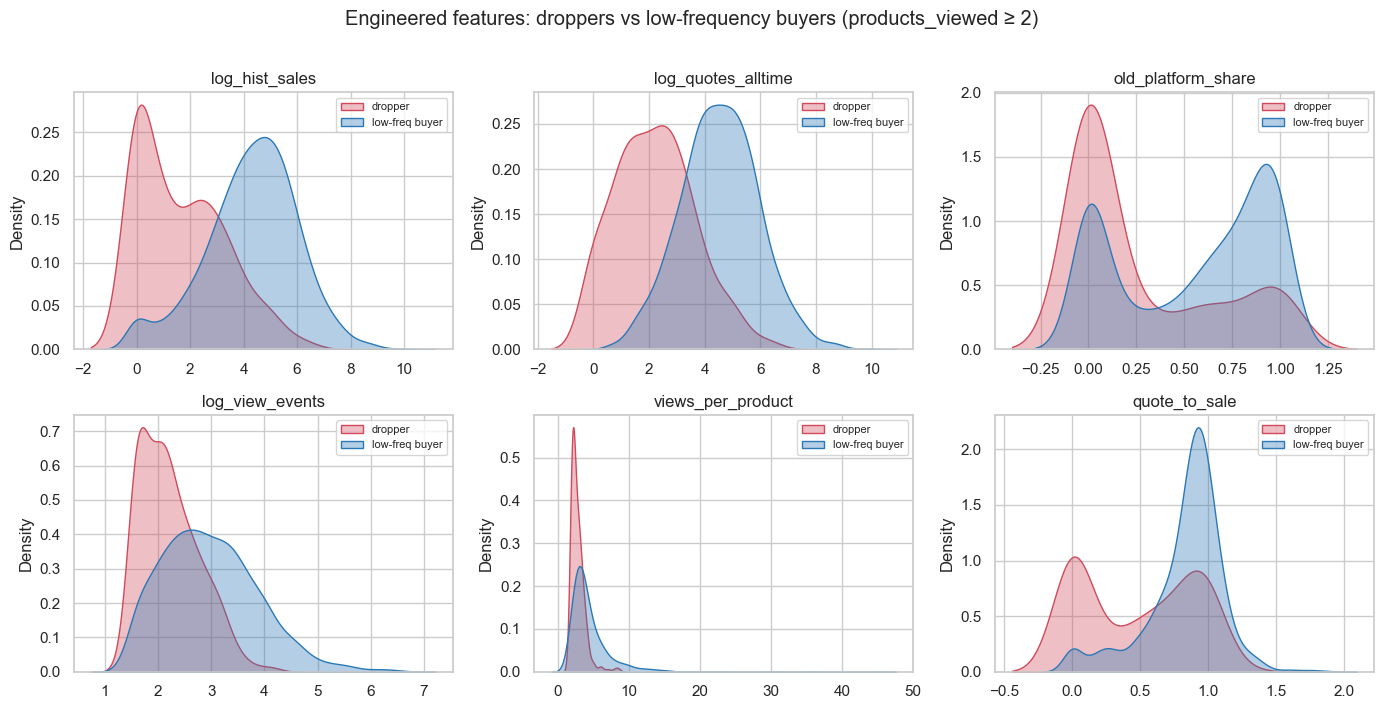

In [8]:
plot_feats = ['log_hist_sales', 'log_quotes_alltime', 'old_platform_share', 'log_view_events',
              'views_per_product', 'quote_to_sale']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), plot_feats):
    sns.kdeplot(data=model_df, x=f, hue='is_dropper', common_norm=False, fill=True,
                alpha=.35, ax=ax, palette={0: '#2a78b5', 1: '#d1495b'}, warn_singular=False)
    ax.set_title(f); ax.set_xlabel('')
    ax.legend(['dropper', 'low-freq buyer'], fontsize=8)
plt.suptitle('Engineered features: droppers vs low-frequency buyers (products_viewed ≥ 2)', y=1.01)
plt.tight_layout(); plt.savefig('plots/fe_distributions.png', dpi=120, bbox_inches='tight'); plt.show()

**Top row: history**

log_hist_sales (sales before Sep 30) is the clearest split.

Droppers peak near 0–1, meaning almost no past sales, with a second bump around 2–3 (about 6–20 sales).
Low-frequency buyers peak around 5 (about 150 sales).
Droppers are mostly agents who never built up a book of business.

log_quotes_alltime tells the same story, slightly shifted.

Droppers centre around 2 (about 6 quotes) and low-frequency buyers around 4.5 (about 90 quotes).
The overlap is bigger than for sales, because some droppers did quote but rarely closed.

old_platform_share (share of past sales on the old platform)

Both groups have a peak at 0, but the dropper peak is much taller.
Part of that red peak is agents with no past sales at all, whose share is set to 0. So this panel partly repeats the “no history” signal.
Low-frequency buyers have a big second peak near 1: most of their history is on the old platform.
A small red bump near 1 is the minority of droppers who sold mostly on the old platform. These are the ones to check for “moved back to the old platform” rather than “stopped.”

**Bottom row: browsing and conversion**

log_view_events (how often they opened products since Sep 30)

Droppers bunch tightly around 1.7–2 (about 5–7 views).
Low-frequency buyers spread further right, with a long tail to 5–6 (150–400 views).
Heavy users of the PWA are almost all still selling, but the middle range overlaps a lot.

views_per_product (how often they return to the same product)

Droppers form a sharp, narrow spike around 2–3: they look at a product a couple of times and leave.
Low-frequency buyers are lower and wider, with a tail past 10. They return to products repeatedly, which looks like comparing options or preparing a sale.
Separating on depth of browsing like this is why this feature ranked top in permutation importance.
The x-axis stretches to 50 because of a few extreme agents, which squeezes the useful part. Clipping it at about 15 or using a log scale would make this panel easier to read.

quote_to_sale (past sales ÷ quotes)

Low-frequency buyers have one tall peak around 0.9–1.0: nearly every quote turns into a sale.
Droppers have two peaks:
Around 0: agents who quoted but never closed. This is the clearest at-risk profile.
Around 0.9: agents who did close well, just at small volume.

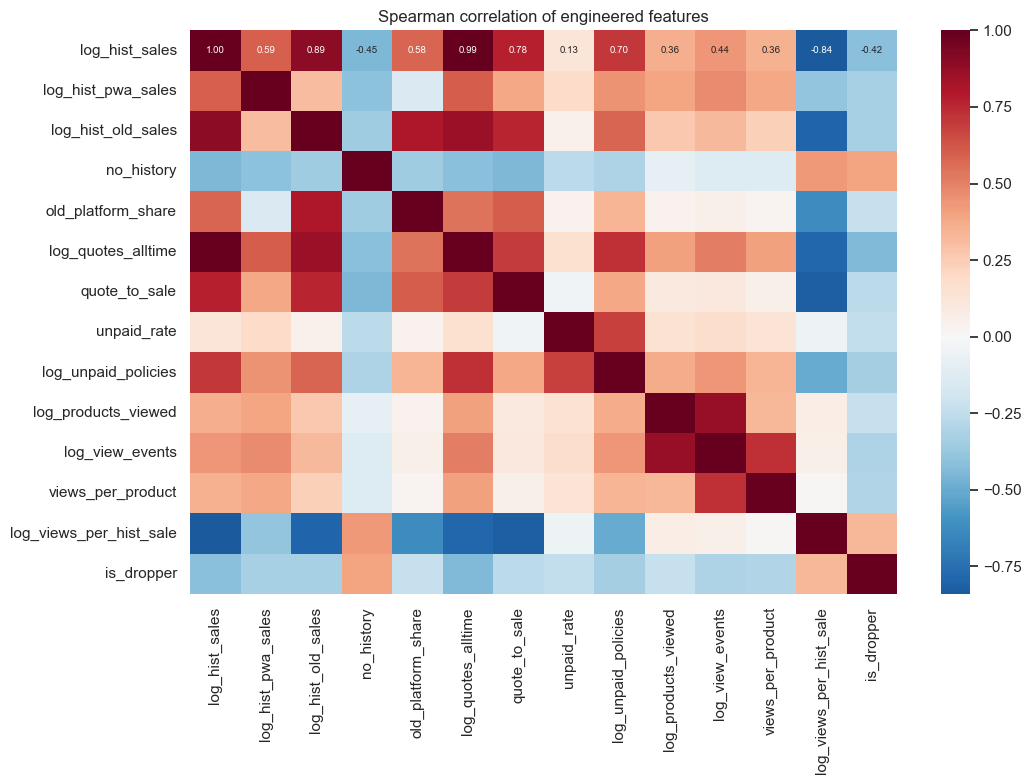

In [9]:
corr = model_df[NUM_FEATURES + ['is_dropper']].corr(method='spearman')
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Spearman correlation of engineered features')
plt.tight_layout(); plt.show()

Several history features move together (hist_sales, hist_old_sales and quotes are strongly correlated). That is fine for tree models; for logistic regression it makes the individual coefficients harder to read, so the logistic model uses an L2 penalty and is read together with permutation importance.

In [10]:
model_df['county'].value_counts().sort_values(ascending=False)

county
Nairobi City         661
Kiambu               117
Mombasa              107
Uasin-Gishu           74
Nakuru                51
Kisumu                50
Kajiado               31
Nyeri                 30
Trans Nzoia           23
Embu                  22
Muranga               18
Bungoma               17
Machakos              17
Narok                 17
Kisii                 15
Kitui                 13
Kakamega              10
Nandi                  9
Meru                   8
Laikipia               7
Makueni                6
Kilifi                 6
Kericho                6
Busia                  6
Migori                 6
Elgeyo / Marakwet      5
Baringo                5
Bomet                  4
Taita / Taveta         4
Siaya                  4
Nairobi                4
Kwale                  4
Homabay                4
Vihiga                 3
NAIROBI                3
Tharaka-Nithi          2
Malindi                2
Eldoret                2
Nyamira                1
Nyandarua         

## 4. Modelling

**Setup**
- Stratified 5-fold cross-validation, repeated on the same folds for every model, so results are comparable.
- Droppers are ~13% of the modelling set, so plain accuracy is misleading (a model that says "nobody drops" scores ~87%). The main metrics are **ROC-AUC** (ranking quality) and **PR-AUC / average precision** (how clean the top of the list is; the baseline is the dropper rate).
- Class weights are balanced so the minority class isn't ignored.

**Models**
1. Dummy baseline (always predicts the class rate)
2. Logistic regression: interpretable
3. Random forest
4. Histogram gradient boosting

In [11]:
# preprocessing pipelines for linear models
pre_linear = ColumnTransformer([
    ('num', StandardScaler(), NUM_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES)])

#preprocessing pipelines for tree-based models
pre_tree = ColumnTransformer([
    ('num', 'passthrough', NUM_FEATURES),  #passthrough means numerical variables are retained in their original form.
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES)])

models = {
    'Dummy (baseline)': Pipeline([('pre', pre_tree), ('clf', DummyClassifier(strategy='prior'))]),  #baseline model that predicts the majority class
    'Logistic regression': Pipeline([('pre', pre_linear),
        ('clf', LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000))]),
    'Random forest': Pipeline([('pre', pre_tree),
        ('clf', RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features='sqrt',
                                       class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1))]),
    'Gradient boosting': Pipeline([('pre', pre_tree),
        ('clf', HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                               min_samples_leaf=20, l2_regularization=1.0,
                                               class_weight='balanced', random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, oof = [], {}
for name, m in models.items():
    s = cross_validate(m, X, y, cv=cv, scoring=['roc_auc', 'average_precision'])
    oof[name] = cross_val_predict(m, X, y, cv=cv, method='predict_proba')[:, 1]
    rows.append({'model': name,
                 'ROC-AUC': f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}",
                 'PR-AUC':  f"{s['test_average_precision'].mean():.3f} ± {s['test_average_precision'].std():.3f}",
                 '_auc': s['test_roc_auc'].mean()})
results = pd.DataFrame(rows).set_index('model')
print(f'Dropper rate (PR-AUC baseline): {y.mean():.3f}')
results.drop(columns='_auc')

Dropper rate (PR-AUC baseline): 0.131


,ROC-AUC,PR-AUC
model,,
Dummy (baseline),0.500 ± 0.000,0.131 ± 0.002
Logistic regression,0.885 ± 0.027,0.609 ± 0.090
Random forest,0.891 ± 0.029,0.638 ± 0.086
Gradient boosting,0.876 ± 0.034,0.616 ± 0.071


#### **Models' Interpretation**

- Dummy(baseline model)
This model has no meaningful ability to distinguish droppers from active agents. Its PR-AUC reflects the proportion of droppers in our dataset.

-Logistic Regression ( ROC-AUC; 0.885, PR-AUC: 0.609)
This model can distinguish between droppers and active agents quite well.

-Random Forest ( ROC-AUC; 0.891, PR-AUC: 0.638)

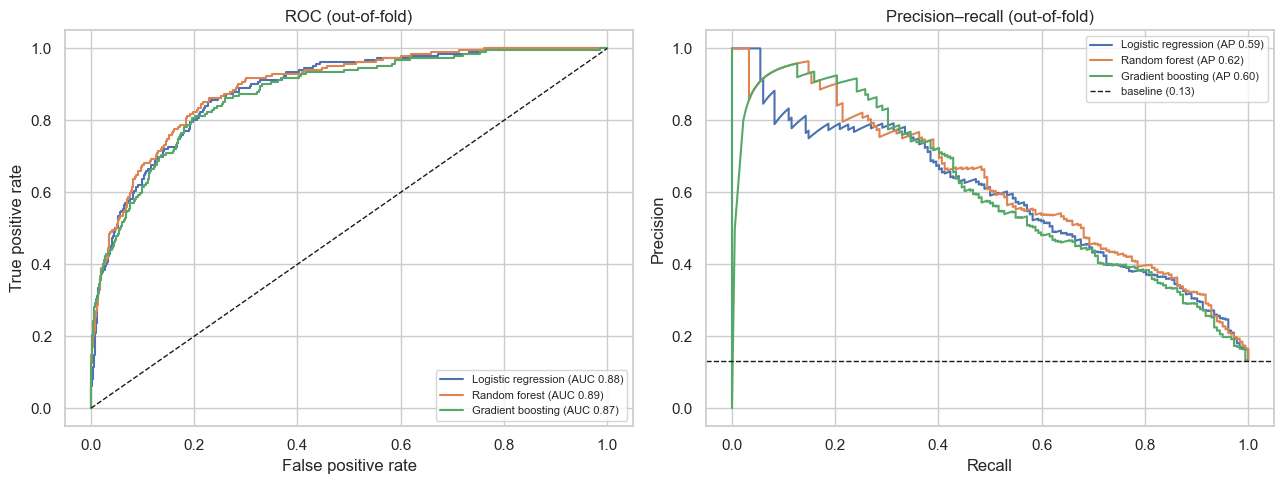

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in oof.items():
    if name.startswith('Dummy'): continue
    fpr, tpr, _ = roc_curve(y, p); prec, rec, _ = precision_recall_curve(y, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y, p):.2f})')
    axes[1].plot(rec, prec, label=f'{name} (AP {average_precision_score(y, p):.2f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set(title='ROC (out-of-fold)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y.mean(), color='k', ls='--', lw=1, label=f'baseline ({y.mean():.2f})')
axes[1].set(title='Precision–recall (out-of-fold)', xlabel='Recall', ylabel='Precision')
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('plots/model_roc_pr.png', dpi=120, bbox_inches='tight'); plt.show()

### Robustness: does the model still work without the undated columns?

`quotes_alltime` and `unpaid_policies` are undated, so part of them may come from after Sep 30. If the model only worked because of them, that would be a warning sign. This refits the best model family without them.

In [13]:
NUM_STRICT = [f for f in NUM_FEATURES if f not in
              ('log_quotes_alltime', 'quote_to_sale', 'unpaid_rate', 'log_unpaid_policies')]

abl = {}
for label, nums in [('All features', NUM_FEATURES), ('Without quotes & unpaid', NUM_STRICT),
                    ('Browsing only', ['log_products_viewed', 'log_view_events', 'views_per_product']),
                    ('History only', ['log_hist_sales', 'log_hist_pwa_sales', 'log_hist_old_sales',
                                      'no_history', 'old_platform_share'])]:
    pipe = Pipeline([('pre', ColumnTransformer([('num', StandardScaler(), nums),
                                                 ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES)])),
                     ('clf', LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000))])

    s = cross_validate(pipe, model_df[nums + CAT_FEATURES], y, cv=cv, scoring=['roc_auc', 'average_precision'])
    abl[label] = {'ROC-AUC': s['test_roc_auc'].mean().round(3), 'PR-AUC': s['test_average_precision'].mean().round(3)}
    
pd.DataFrame(abl).T

,ROC-AUC,PR-AUC
All features,0.885,0.609
Without quotes & unpaid,0.886,0.602
Browsing only,0.770,0.292
History only,0.859,0.486


## 5. What drives the prediction?

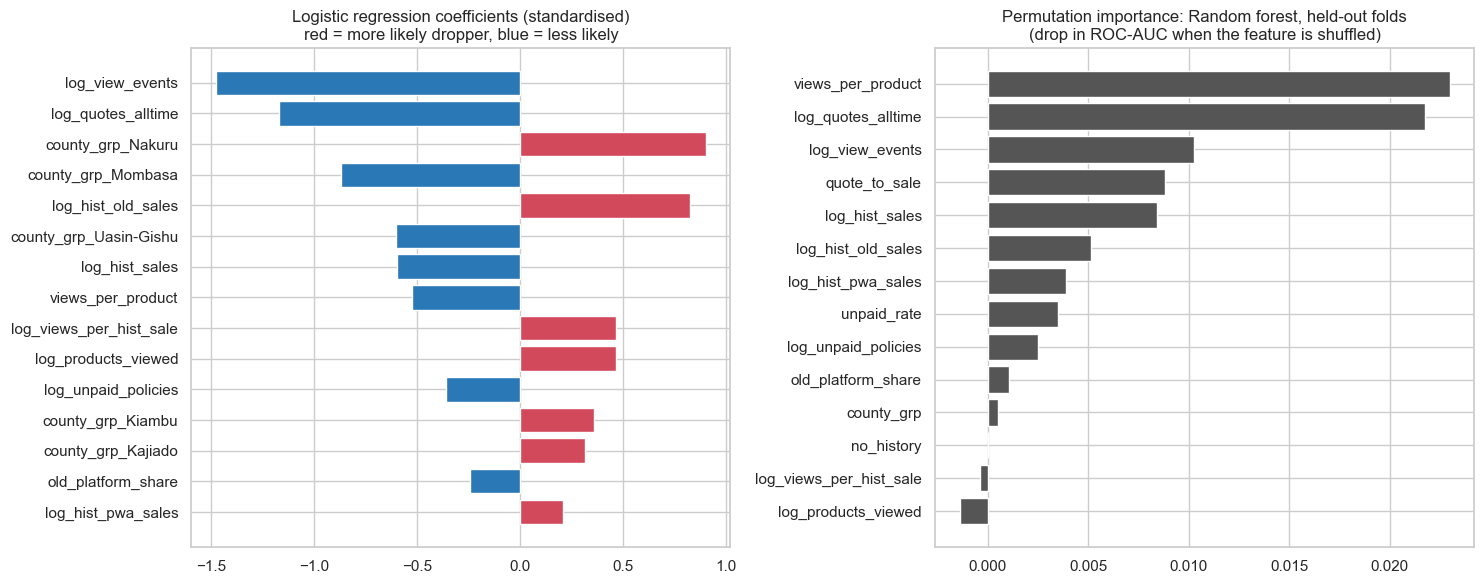

Best model by CV ROC-AUC: Random forest


In [14]:
logit = models['Logistic regression'].fit(X, y)
names = logit.named_steps['pre'].get_feature_names_out()
coef = pd.Series(logit.named_steps['clf'].coef_[0], index=[n.split('__')[1] for n in names])
coef = coef.reindex(coef.abs().sort_values(ascending=False).index)

best_name = results['_auc'].drop('Dummy (baseline)').idxmax()
from sklearn.base import clone
# Permutation importance on held-out folds (on training data a random forest would look falsely flat)
imps = []
for tr, te in cv.split(X, y):
    m = clone(models[best_name]).fit(X.iloc[tr], y.iloc[tr])
    pi = permutation_importance(m, X.iloc[te], y.iloc[te], scoring='roc_auc', n_repeats=10,
                                random_state=RANDOM_STATE, n_jobs=-1)
    imps.append(pi.importances_mean)
perm = pd.Series(np.mean(imps, axis=0), index=FEATURES).sort_values()
best = models[best_name].fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
c = coef.head(15)[::-1]
axes[0].barh(c.index, c.values, color=np.where(c.values > 0, '#d1495b', '#2a78b5'))
axes[0].set_title('Logistic regression coefficients (standardised)\nred = more likely dropper, blue = less likely')
axes[1].barh(perm.index, perm.values, color='#555')
axes[1].set_title(f'Permutation importance: {best_name}, held-out folds\n(drop in ROC-AUC when the feature is shuffled)')
plt.tight_layout(); plt.savefig('plots/model_drivers.png', dpi=120, bbox_inches='tight'); plt.show()
print('Best model by CV ROC-AUC:', best_name)

**For my learning**

How to read the two charts
Left chart: red bars are things that make someone more likely to leave, and blue bars make them less likely. Longer bars mean a stronger effect.
Right chart: this shows how much the tool relies on each piece of information. A longer bar means the tool gets worse if that information is taken away. It shows how important each item is, not whether it pushes people toward staying or leaving.

**Findings**

Agents who regularly browse and create quotes always stay. People who rarely log in or browse are the most likely to leave. Low activity tells us someone is probably on their way out, but it doesn’t explain why. Activity dropping is the clearest sign someone is about to leave.

Past sales matter and where they were done. People with a solid sales record tend to stay. But people whose sales were mostly on the old platform are more likely to leave. In other words, people who never really moved their business onto the new app are the ones drifting away.

Location plays a role(although it needs more evidence). One version of the tool suggested people in Nakuru leave more often and people in Mombasa less often. The other version found location made almost no difference. We’ll treat this as something to check, not a conclusion.

## 6. Choosing a threshold for follow-up

A probability is only useful once it becomes a decision. Below are the out-of-fold results at a few cut-offs, using the best model. Lower cut-offs catch more droppers but put more still-selling agents on the call list.

In [15]:
p_best = oof[best_name]
tab = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_best >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    tab.append({'threshold': t, 'flagged': tp + fp, 'droppers caught': tp, 'recall': round(tp / (tp + fn), 2),
                'precision': round(tp / max(tp + fp, 1), 2), 'still-selling flagged': fp})
thr_table = pd.DataFrame(tab).set_index('threshold')
thr_table

,flagged,droppers caught,recall,precision,still-selling flagged
threshold,,,,,
0.3,390,150,0.82,0.38,240
0.4,291,130,0.71,0.45,161
0.5,222,117,0.64,0.53,105
0.6,179,100,0.55,0.56,79
0.7,144,90,0.49,0.62,54


Takes the probabilities generated by the RFModel and tests different thresholds to determine how many agents would be flagged as potential droppers

Recall captures, of all the positives(droppers) captured, how many were actually positives

Precision captures; Out of all the agents flagged as potential droppers, what proportion are actually droppers?

F1-optimal threshold: 0.52

                precision    recall  f1-score   support

low-freq buyer       0.94      0.92      0.93      1204
       dropper       0.54      0.64      0.59       182

      accuracy                           0.88      1386
     macro avg       0.74      0.78      0.76      1386
  weighted avg       0.89      0.88      0.89      1386



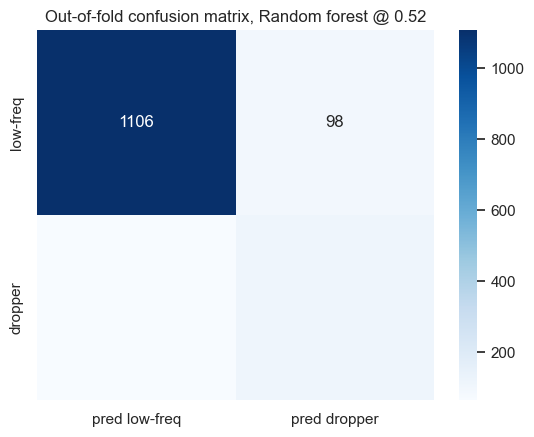

In [16]:
# Threshold that maximises F1 on out-of-fold predictions
prec, rec, thr = precision_recall_curve(y, p_best)

f1 = 2 * prec * rec / (prec + rec + 1e-9)

THRESH = float(thr[np.argmax(f1[:-1])])

print(f'F1-optimal threshold: {THRESH:.2f}\n')

print(classification_report(y, (p_best >= THRESH).astype(int), target_names=['low-freq buyer', 'dropper']))

cm = confusion_matrix(y, (p_best >= THRESH).astype(int))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['pred low-freq', 'pred dropper'],
            yticklabels=['low-freq', 'dropper'])
            
plt.title(f'Out-of-fold confusion matrix, {best_name} @ {THRESH:.2f}'); plt.show()

What it means

Out of 1,386 customers, 182 (about 13%) actually dropped. Using a cutoff of 0.52, the model:

Caught 116 of the 182 droppers (64%). These are people you could have reached out to in time.
Missed 66 droppers (36%). They looked like ordinary low-frequency buyers to the model.
Flagged 214 people in total, and 116 of them really were droppers (54%). So about 1 in 2 flags is correct and the other half are false alarms. That’s still about 4× better than picking people at random, where only 13% would be droppers.
Correctly left 1,106 of the 1,204 regular customers alone (92%)

## 7. Scoring: who to follow up

The model is refit on the full modelling set and used to score every agent, including the 1-product droppers that were set aside.

The most useful list is the **low-frequency buyers the model scores as dropper-like**. They are still selling today but look like agents who have already stopped, so they are the earliest warning. Each row shows the evidence behind the score.

In [17]:
all_df, _ = engineer(df, TOP_COUNTIES)

all_df['dropper_risk'] = best.predict_proba(all_df[FEATURES])[:, 1]

# Out-of-fold scores are more honest for agents the model was trained on
all_df.loc[all_df['products_viewed'] >= 2, 'dropper_risk'] = p_best
all_df['risk_band'] = pd.cut(all_df['dropper_risk'], [0, 0.3, THRESH, 1.0001],
                             labels=['Low', 'Medium', 'High'], include_lowest=True)

watch = (all_df[(all_df.is_dropper == 0) & (all_df.dropper_risk >= THRESH)]
         .sort_values('dropper_risk', ascending=False)
         [['user_name', 'county', 'dropper_risk', 'sales_since_sep30', 'hist_sales', 'old_platform_share',
           'quotes_alltime', 'products_viewed', 'view_events']])
print(f'Low-frequency buyers who look like droppers (risk ≥ {THRESH:.2f}): {len(watch)}')
watch.head(20).round(2)

Low-frequency buyers who look like droppers (risk ≥ 0.52): 98


,user_name,county,dropper_risk,sales_since_sep30,hist_sales,old_platform_share,quotes_alltime,products_viewed,view_events
252,Nicholas Mabonga,Uasin-Gishu,0.98,1,0,0.0,1,2,4
114,Twaha Ibrahim,Kilifi,0.94,1,0,0.0,1,3,8
122,Phanice Matani,Nakuru,0.93,1,0,0.0,2,3,8
275,LENCER KASERA AGENCY,Nairobi City,0.93,1,1,0.0,2,2,6
26,Bridgid Muloki,Nairobi City,0.92,1,0,0.0,1,5,15
259,Jacob Muthui Musyoki,Nairobi City,0.91,1,2,1.0,3,2,5
245,margaret mutwasi,Nakuru,0.91,1,0,0.0,3,2,7
357,Ivoynne Imali,Nairobi City,0.91,2,0,0.0,4,3,6
206,Nancy Akinyi,Meru,0.90,1,2,0.0,3,2,4
503,JOHN MGHANGA,NAIROBI,0.90,2,0,0.0,5,2,6


In [18]:
print(pd.crosstab(all_df['risk_band'], all_df['is_dropper'].map({0: 'low-freq buyer', 1: 'dropper'}), margins=True))

is_dropper  dropper  low-freq buyer   All
risk_band                                
Low              42             964  1006
Medium           67             142   209
High            255              98   353
All             364            1204  1568


**Droppers the model did *not* expect** (low risk score but did stop). These look like healthy agents on paper, so the most likely explanation is that they moved their selling back to the old platform or offline. They are worth a check on platform attribution before treating them as lost.

In [19]:
surprise = (all_df[(all_df.is_dropper == 1) & (all_df.dropper_risk < 0.3)]
            .sort_values('hist_sales', ascending=False)
            [['user_name', 'county', 'dropper_risk', 'hist_sales', 'old_platform_share', 'quotes_alltime',
              'products_viewed', 'view_events', 'last_sale_date']])
print(f'Unexpected droppers: {len(surprise)}')
surprise.head(15).round(2)

Unexpected droppers: 42


,user_name,county,dropper_risk,hist_sales,old_platform_share,quotes_alltime,products_viewed,view_events,last_sale_date
1502,Talyncy Ins. Agency,Kiambu,0.26,1076,0.87,1073,1,2,2026-04-29
1296,Nancy Obonyo Ondieki,Kisii,0.08,575,1.00,579,3,6,2026-09-13
1305,Priscillah Wanjohi,Laikipia,0.02,434,0.61,448,2,8,2026-09-29
1504,Joseph Macharia Karimi,Nairobi City,0.11,304,0.96,236,1,2,2026-09-25
1257,LOISE KIBE,Kajiado,0.12,275,0.61,254,4,10,2026-09-16
1215,Joseph Musina,Siaya,0.02,178,0.99,164,8,22,2026-09-25
1342,Daniel Ndiritu,Nairobi City,0.19,164,0.97,165,2,4,2026-09-20
1219,Franjis Insurance Agency,Nairobi City,0.06,153,0.64,161,7,16,2026-09-25
1297,Vickim ins Agency,Nakuru,0.20,143,0.97,145,3,6,2026-09-23
1252,Margaret Wambugu,Nairobi City,0.05,134,0.31,154,4,11,2026-09-12


In [21]:
out_cols = ['user_name', 'county', 'email', 'phone_number', 'is_dropper', 'dropper_risk', 'risk_band',
            'sales_since_sep30', 'hist_sales', 'hist_pwa_sales', 'hist_old_sales', 'old_platform_share',
            'quotes_alltime', 'quote_to_sale', 'unpaid_rate', 'products_viewed', 'view_events', 'views_per_product']
scored = all_df[out_cols].sort_values('dropper_risk', ascending=False)
scored['agent_status'] = scored['is_dropper'].map({0: 'Low-freq buyer', 1: 'Dropper'})
scored.to_csv('agent_dropper_risk_scores.csv', index=False)
print('Saved agent_dropper_risk_scores.csv', scored.shape)

Saved agent_dropper_risk_scores.csv (1568, 19)


## 8. Summary

**Fixes before modelling**
- The 3 test accounts are now removed from the combined table (in `dropper.ipynb` they were removed from copies but `combined` was built from the originals).
- `sales_since_sep30`, `viewed_per_sale` and every last-sale-date column were excluded. They encode the label: the last-sale date alone splits the groups perfectly at Sep 30.
- 182 droppers who viewed only 1 product were set aside, because the low-frequency sheet has no agent below 2 products viewed. Leaving them in would let the model "learn" the sheet filter rather than behaviour.

**Model performance (5-fold CV, 1,386 agents, 13% droppers)**
- All three models land close together: ROC-AUC ≈ 0.88–0.89 and PR-AUC ≈ 0.61–0.64, against a baseline of 0.13. The random forest is marginally best; the logistic regression is nearly as good and much easier to explain.
- The result holds without the undated quote and unpaid columns (ROC-AUC 0.886), so it is not riding on possible leakage there.
- **History matters more than browsing.** History alone gives ROC-AUC 0.86; browsing alone gives 0.77; together they give 0.89.

**What separates droppers from agents who keep selling**
1. **Small book of business.** Median history is 2.5 sales and 7.5 quotes for droppers against 83 sales and 92 quotes for low-frequency buyers.
2. **Shallow browsing.** Droppers come back to a product less often (2.5 views per product vs 3.5) and have fewer view events overall (7 vs 17). Revisiting the same product looks like an agent preparing a sale; a single look does not.
3. **Weaker quote conversion.** Droppers turned about half their quotes into sales, against close to 9 in 10 for low-frequency buyers. Small agents who struggle to close look most at risk.
4. **Old-platform lean: a weak and mixed signal.** In the logistic model, more old-platform sales at the same total history raises risk, but the random forest gives platform features little weight. Treat it as a hint that some "droppers" went back to the old platform, not as a finding.
5. County effects exist (Nakuru higher, Mombasa lower) but are based on small groups and shouldn't be acted on alone.

**How to use the scores**
- At the F1-optimal threshold (~0.5), the model catches about 65% of droppers with about half of flagged agents being true droppers. Use a lower threshold (0.3–0.4) when the goal is to miss as few as possible and a call is cheap.
- **103 low-frequency buyers score as high risk.** Most are new agents with 1–2 sales since Sep 30 and almost no history. They are the early-warning list: still selling today, but they look like agents who stopped. Onboarding support for them is likely to pay off more than chasing large agents.
- **41 droppers scored low risk**, including several with hundreds of past sales mostly on the old platform (e.g. Talyncy Ins. Agency, Nancy Obonyo Ondieki). Check platform attribution for these before treating them as lost. They may simply have gone back to the old platform.
- All 1,568 agents with scores and evidence columns are saved in `agent_dropper_risk_scores.csv`.

**Limits**
- The window since Sep 30 is about a month. Agents who sell monthly can be labelled droppers by bad luck of timing.
- The label is "no PWA-tracked policy since Sep 30", not "stopped selling". The data still can't tell paid from unpaid recent business or which platform recent sales came from.
- Quotes and unpaid policies are undated. The robustness check shows the model doesn't depend on them, but their exact values mix periods.
- This is one snapshot. The real test is to score agents now and check in a month who actually stopped: a time-based validation that this data can't provide yet.

In [ ]:
DD

---
# Part 2: Assumptions and tuning plan

The correlation matrix and the first round of models point to what to tune next and which assumptions to state openly.

## Assumptions we are making (and how to check each one)

| # | Assumption | Why we need it | How to check / when it breaks |
|---|---|---|---|
| A1 | **"Dropper" means no PWA-tracked policy since Sep 30.** It does not mean the agent stopped selling. | The data has no dated sales by platform | Hand-check a sample of droppers on the old platform; the 41 "unexpected droppers" are the first place to look |
| A2 | **Sales before Sep 30 = lifetime sales − sales since Sep 30.** Recent PWA sales are taken out of `pwa_sales`. | Lifetime columns mix the two periods | About 5% of low-freq buyers have more recent sales than PWA sales, so some recent sales were on the old platform. The split is an approximation |
| A3 | **Quotes and unpaid policies are mostly historical.** | These columns are undated | Robustness check: removing them leaves the score unchanged (ROC-AUC 0.886 vs 0.885) |
| A4 | **Browsing is measured the same way for both groups** (tracked since Sep 30) | Needed to compare view counts | Holds only if tracking went live for every agent at the same time |
| A5 | **Agents with 2+ products viewed are comparable across the two sheets** | The low-freq sheet was filtered at ≥2 | Sensitivity test below raises the cut-off to ≥3 |
| A6 | **One snapshot stands in for the future.** Patterns that separate droppers now will hold next month. | No second time period yet | Score agents now and compare with the November extract |
| A7 | **The ~1-month window is long enough to call someone a dropper** | Some agents sell monthly | Agents whose usual gap between sales is longer than a month will be labelled by chance. Re-label once the window is 60+ days |
| A8 | **Missing a real dropper costs more than an unnecessary call** (assumed 3:1) | Needed to set the follow-up cut-off | A business decision. Change `COST_FN` below if the team sees it differently |

## What we can tune

1. **Features.** The correlation matrix shows the history columns are near-duplicates (lifetime sales, old-platform sales, quotes, unpaid ≈ 0.9). Test a **pruned** set that keeps one column per idea.
2. **Hyperparameters.** Use randomised search inside **nested** cross-validation, so the score reported is not the same score used to choose the settings.
3. **Class imbalance.** Compare balanced class weights with none (droppers are 13% of the modelling set).
4. **Data cut-off (A5).** Model on products_viewed ≥ 3 and see whether the conclusions change.
5. **Decision threshold (A8).** Choose by cost, not F1.
6. **Calibration.** Check that a risk of 0.6 really means about 60% of those agents are droppers, so the score can be read as a probability.

**Things not to tune, because they would bring the leakage back:** `days_since_last_sale`, `sales_since_sep30`, `viewed_per_sale`, `last_sale_date`.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from scipy.stats import randint, uniform, loguniform

def make_pre(nums, scale):
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', nums),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_FEATURES)])

def cv_score(pipe, data, nums, yv):
    s = cross_validate(pipe, data[nums + CAT_FEATURES], yv, cv=cv, scoring=['roc_auc', 'average_precision'])
    return s['test_roc_auc'].mean(), s['test_average_precision'].mean()

### Tuning 1: features — full vs pruned

The pruned set keeps one column per idea: size of history, platform mix, quote conversion, unpaid rate, browsing volume, revisit depth and location.

In [ ]:
NUM_PRUNED = ['log_hist_sales', 'old_platform_share', 'quote_to_sale', 'unpaid_rate',
              'log_view_events', 'views_per_product']
rows = []
for fs_name, nums in [('Full (13 numeric)', NUM_FEATURES), ('Pruned (6 numeric)', NUM_PRUNED)]:
    for mname, clf, scale in [
        ('Logistic', LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000), True),
        ('Random forest', RandomForestClassifier(n_estimators=500, min_samples_leaf=5, class_weight='balanced_subsample',
                                                 random_state=RANDOM_STATE, n_jobs=-1), False)]:
        auc, ap = cv_score(Pipeline([('pre', make_pre(nums, scale)), ('clf', clf)]), model_df, nums, y)
        rows.append({'features': fs_name, 'model': mname, 'ROC-AUC': round(auc, 3), 'PR-AUC': round(ap, 3)})
feat_cmp = pd.DataFrame(rows).set_index(['features', 'model'])
feat_cmp

### Tuning 2: hyperparameters with nested cross-validation

An inner 3-fold randomised search picks the settings and an outer 5-fold loop scores them on data the search never saw. Class weighting is part of the search (tuning item 3).

In [ ]:
search_spaces = {
    'Logistic regression': (
        Pipeline([('pre', make_pre(NUM_FEATURES, True)), ('clf', LogisticRegression(max_iter=5000, solver='liblinear'))]),
        {'clf__C': loguniform(1e-3, 10), 'clf__penalty': ['l1', 'l2'], 'clf__class_weight': [None, 'balanced']}),
    'Random forest': (
        Pipeline([('pre', make_pre(NUM_FEATURES, False)),
                  ('clf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
        {'clf__max_depth': [None, 4, 6, 8, 12], 'clf__min_samples_leaf': randint(1, 20),
         'clf__max_features': ['sqrt', 0.3, 0.5, 0.8], 'clf__class_weight': [None, 'balanced_subsample']}),
    'Gradient boosting': (
        Pipeline([('pre', make_pre(NUM_FEATURES, False)),
                  ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
        {'clf__learning_rate': loguniform(0.01, 0.2), 'clf__max_iter': randint(100, 500),
         'clf__max_leaf_nodes': randint(4, 31), 'clf__min_samples_leaf': randint(10, 60),
         'clf__l2_regularization': loguniform(1e-3, 10), 'clf__class_weight': [None, 'balanced']}),
}
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)
tuned_rows, tuned_oof, best_params = [], {}, {}
for name, (pipe, space) in search_spaces.items():
    search = RandomizedSearchCV(pipe, space, n_iter=20, scoring='average_precision', cv=inner,
                                random_state=RANDOM_STATE, n_jobs=-1)
    s = cross_validate(search, X, y, cv=cv, scoring=['roc_auc', 'average_precision'])
    tuned_oof[name] = cross_val_predict(search, X, y, cv=cv, method='predict_proba')[:, 1]
    best_params[name] = search.fit(X, y).best_params_
    tuned_rows.append({'model': name,
                       'untuned ROC-AUC': results.loc[name, 'ROC-AUC'], 'tuned ROC-AUC': f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}",
                       'untuned PR-AUC': results.loc[name, 'PR-AUC'], 'tuned PR-AUC': f"{s['test_average_precision'].mean():.3f} ± {s['test_average_precision'].std():.3f}",
                       '_ap': s['test_average_precision'].mean()})
tuned = pd.DataFrame(tuned_rows).set_index('model')
display(tuned.drop(columns='_ap'))
for k, v in best_params.items():
    print(k, {p.replace('clf__', ''): (round(x, 4) if isinstance(x, float) else x) for p, x in v.items()})

### Tuning 4: sensitivity to the products-viewed cut-off (assumption A5)

If the model only worked because of how the sheets were filtered, raising the cut-off would change the results sharply.

In [ ]:
sens = []
for cut in [2, 3, 4]:
    sub = model_df[model_df['products_viewed'] >= cut]
    pipe = Pipeline([('pre', make_pre(NUM_FEATURES, True)),
                     ('clf', LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000))])
    auc, ap = cv_score(pipe, sub, NUM_FEATURES, sub['is_dropper'])
    sens.append({'products_viewed ≥': cut, 'agents': len(sub), 'droppers': int(sub.is_dropper.sum()),
                 'dropper rate': round(sub.is_dropper.mean(), 3), 'ROC-AUC': round(auc, 3), 'PR-AUC': round(ap, 3)})
pd.DataFrame(sens).set_index('products_viewed ≥')

### Tuning 5 and 6: cost-based threshold and calibration

In [ ]:
FINAL_NAME = tuned['_ap'].idxmax()
p_final = tuned_oof[FINAL_NAME]
COST_FN, COST_FP = 3, 1   # assumption A8: missing a dropper costs 3x an unnecessary call

ts = np.linspace(0.05, 0.95, 91)
costs = [COST_FN * ((p_final < t) & (y == 1)).sum() + COST_FP * ((p_final >= t) & (y == 0)).sum() for t in ts]
COST_THRESH = float(ts[int(np.argmin(costs))])
pred = (p_final >= COST_THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
print(f'Final model: {FINAL_NAME} (tuned) | cost-optimal threshold = {COST_THRESH:.2f}')
print(f'Flagged {tp+fp} agents: {tp} droppers caught of {tp+fn} (recall {tp/(tp+fn):.2f}), precision {tp/(tp+fp):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ts, costs); axes[0].axvline(COST_THRESH, color='#d1495b', ls='--')
axes[0].set(title=f'Total cost by threshold (missed dropper = {COST_FN}, wasted call = {COST_FP})', xlabel='threshold', ylabel='cost')
frac_pos, mean_pred = calibration_curve(y, p_final, n_bins=8, strategy='quantile')
axes[1].plot(mean_pred, frac_pos, 'o-', label=FINAL_NAME); axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='perfectly calibrated')
axes[1].set(title='Calibration (out-of-fold)', xlabel='predicted risk', ylabel='actual share of droppers'); axes[1].legend()
plt.tight_layout(); plt.savefig('plots/tuning_threshold_calibration.png', dpi=120, bbox_inches='tight'); plt.show()

Balanced class weights push predicted risks upwards, so the raw scores overstate the chance of dropping. Calibrating with isotonic regression (fitted inside the folds) fixes this, so the final scores can be read as probabilities.

In [ ]:
final_pipe, final_space = search_spaces[FINAL_NAME]
final_est = clone(final_pipe).set_params(**best_params[FINAL_NAME])
calibrated = CalibratedClassifierCV(final_est, method='isotonic', cv=5)
p_cal = cross_val_predict(calibrated, X, y, cv=cv, method='predict_proba')[:, 1]
fp_c, mp_c = calibration_curve(y, p_cal, n_bins=8, strategy='quantile')
print(f'ROC-AUC before/after calibration: {roc_auc_score(y, p_final):.3f} / {roc_auc_score(y, p_cal):.3f}')
print(f'Mean predicted risk before/after: {p_final.mean():.3f} / {p_cal.mean():.3f}  (actual dropper rate {y.mean():.3f})')
plt.figure(figsize=(5.5, 4.5))
plt.plot(mean_pred, frac_pos, 'o-', label='uncalibrated'); plt.plot(mp_c, fp_c, 's-', label='isotonic-calibrated')
plt.plot([0, 1], [0, 1], 'k--', lw=1); plt.xlabel('predicted risk'); plt.ylabel('actual share of droppers'); plt.legend()
plt.title('Calibration before vs after'); plt.tight_layout(); plt.show()

costs_c = [COST_FN * ((p_cal < t) & (y == 1)).sum() + COST_FP * ((p_cal >= t) & (y == 0)).sum() for t in ts]
CAL_THRESH = float(ts[int(np.argmin(costs_c))])
print(f'Cost-optimal threshold on calibrated scores: {CAL_THRESH:.2f} '
      f'(≈ {COST_FP}/({COST_FN}+{COST_FP}) = {COST_FP/(COST_FN+COST_FP):.2f} in theory)')

In [ ]:
# Final scores: tuned + calibrated model, out-of-fold for modelling agents, refit for the 1-product droppers
calibrated.fit(X, y)
all_df['dropper_risk_v2'] = calibrated.predict_proba(all_df[FEATURES])[:, 1]
all_df.loc[all_df['products_viewed'] >= 2, 'dropper_risk_v2'] = p_cal
all_df['flag_followup'] = (all_df['dropper_risk_v2'] >= CAL_THRESH).astype(int)
v2 = all_df.loc[all_df.is_dropper == 0]
print(f'Still-selling agents flagged for follow-up: {v2.flag_followup.sum()} of {len(v2)}')
print(f'Overlap with the first-round watch list: {v2.loc[v2.flag_followup == 1].index.isin(watch.index).sum()} of {len(watch)}')

scored2 = all_df[out_cols + ['dropper_risk_v2', 'flag_followup']].sort_values('dropper_risk_v2', ascending=False)
scored2['agent_status'] = scored2['is_dropper'].map({0: 'Low-freq buyer', 1: 'Dropper'})
scored2.to_csv('agent_dropper_risk_scores.csv', index=False)
print('Updated agent_dropper_risk_scores.csv with dropper_risk_v2 and flag_followup')

## Part 2 summary: what tuning changed

| Tuning lever | Result | Decision |
|---|---|---|
| Pruned features (13 → 6 numeric) | Same performance (RF ROC-AUC 0.897 vs 0.891, PR-AUC 0.632 vs 0.638) | **Use the pruned set going forward.** Fewer columns are easier to explain and less exposed to the collinearity seen in the correlation matrix |
| Hyperparameters (nested CV) | Small gains: gradient boosting PR-AUC 0.626 → 0.649, logistic 0.609 → 0.635. All within one standard deviation | The data, not the settings, sets the ceiling. Don't spend more time on grid searches |
| Class weights | The search kept "balanced" for boosting and dropped it for logistic regression and the random forest | Either works once the threshold is set by cost |
| products_viewed cut-off (A5) | ROC-AUC stays 0.885–0.915 at ≥2, ≥3 and ≥4 | **The model is not riding on the sheet filter.** Assumption A5 holds |
| Cost-based threshold (A8, 3:1) | Calibrated cut-off ≈ 0.39. It flags 93 still-selling agents for follow-up, 81 of them already on the first-round list | The follow-up list is stable across model versions |
| Calibration | Mean predicted risk drops from 0.24 to 0.16 (actual rate 0.13) | Use `dropper_risk_v2` when quoting a score as a probability |

**Bottom line:** tuning confirms the first-round result (ROC-AUC ≈ 0.89, PR-AUC ≈ 0.63–0.65) instead of improving on it much. The next real gain will come from **better data, not a better model**:

1. **Dated sales by platform.** This removes approximations A1 and A2 and shows directly whether a "dropper" moved back to the old platform.
2. **A second snapshot (the November extract).** This allows a proper time-based test (A6): score agents in October, check who actually stopped in November.
3. **A longer window (60+ days)** so monthly sellers aren't labelled droppers by chance (A7).
4. **Paid vs unpaid status for recent policies**, to separate real business from activity.
5. **Agent tenure / onboarding date.** Most flagged agents are new, so tenure is likely the single most useful missing feature.
